# GoEmotions pt-BR: tratamento, dataset unificado e EDA

Notebook do grupo **Equilibrium (Residência IA)** sobre o
[`emotional-dataset-pt-br`](https://github.com/Equilibrium-Residencia-IA/emotional-dataset-pt-br):
54.263 comentários do Reddit traduzidos para pt-BR, com 28 rótulos de emoção (um comentário pode ter mais de um).

**Roteiro**
1. Carga: junta todos os `translated/*_translated.json`
2. Integridade dos dados
3. Problemas encontrados no texto
4. Tratamento
5. **Dataset unificado** (train + dev + test em um só)
6. **EDA e insights** sobre o dataset unificado
7. Exportação (dataset unificado e divisão train/validation/test)
8. Conclusões e pontos de melhoria

> Premissa: o dataset vai treinar uma **rede neural que classifica as emoções** de mensagens em português. Por isso, é tratado
> tudo que não é texto pt-BR com conteúdo emocional útil. Os exemplos exibidos no notebook passam por um filtro
> que esconde comentários com conteúdo sexual, palavrões pesados ou ofensas (o dataset em si não é alterado). As decisões ajustáveis ficam na célula de configuração.

## 1. Configuração e carga

In [1]:
import os, re, glob, json, subprocess, html
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# ---------------- Configuração ----------------
REPO_URL  = "https://github.com/Equilibrium-Residencia-IA/emotional-dataset-pt-br.git"
REPO_DIR  = "emotional-dataset-pt-br"
DATA_DIR  = os.path.join(REPO_DIR, "translated")
OUT_DIR   = "data_processed"

MIN_WORDS          = 2      # textos com menos palavras de conteúdo (sem contar [NAME] etc.) são descartados
DROP_NEUTRAL_MIXED = True   # tira o rótulo 'neutral' quando ele aparece junto com uma emoção
DROP_NEUTRAL_ONLY  = False  # True = descarta comentários só 'neutral'
# ----------------------------------------------

PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
SEQ = sns.light_palette(PAL[0], as_cmap=True)
mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "figure.dpi": 110,
    "axes.prop_cycle": mpl.cycler(color=PAL),
})
pd.set_option("display.max_colwidth", 140)
fmt = lambda v: f"{v:,.0f}".replace(",", ".")

# Filtro usado SÓ nos exemplos exibidos (o dataset não é alterado): esconde comentários com conteúdo
# sexual, palavrões pesados, ofensas e xingamentos, para o notebook poder ser lido sem esse tipo de texto.
CONTEUDO_PESADO = re.compile(
    r"(?i)\b(?:goz\w*|porra\w*|caralh\w*|fod\w*|foda\w*|puta\w*|put[ao]s?|pqp|fdp|vsf|vtnc|tnc|buceta\w*|"
    r"xoxota\w*|xereca\w*|piroca\w*|pica|pau|rola|pinto|p[êe]nis|vagina\w*|cu|cus|cuz[ãa]o|arromb\w*|"
    r"bunda\w*|peit[ãa]o|tes[ãa]o|transa\w*|trepa\w*|sexo|sexual\w*|porn\w*|nudes?|punhet\w*|boquete\w*|"
    r"chupa\w*|mamar|orgasm\w*|masturb\w*|estupr\w*|pedof\w*|viad\w*|bicha\w*|baitola|sapat[ãa]o|"
    r"traveco|retardad\w*|mongol\w*|vadia\w*|vagabund\w*|piranha\w*|safad\w*|prostitu\w*|merda\w*|"
    r"bosta\w*|cacete|desgra[çc]\w*|nazis\w*|nigg\w*|crioul\w*|macac[oa]s?|cag\w*)\b")
eh_pesado = lambda s: s.str.contains(CONTEUDO_PESADO, regex=True)

def amostra_segura(df, n, random_state=None, col="text"):
    """Amostra só entre os comentários sem conteúdo pesado (usada nos exemplos exibidos)."""
    ok = df[~eh_pesado(df[col])]
    return ok.sample(min(n, len(ok)), random_state=random_state)

if not os.path.isdir(DATA_DIR):
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)

In [2]:
files = sorted(glob.glob(os.path.join(DATA_DIR, "*_translated.json")))
raw = pd.concat([pd.DataFrame(json.load(open(f, encoding="utf-8"))) for f in files], ignore_index=True)
print(f"{len(files)} arquivos -> {raw.shape[0]:,} comentários".replace(",", "."))
raw[["id", "split", "translated_text", "emotions"]].head()

1093 arquivos -> 54.263 comentários


,id,split,translated_text,emotions
0,edgurhb,dev,Isso é em Nova Orleans?? Tenho muita pinta de ser em Nova Orleans.,[neutral]
1,ee84bjg,dev,"Você sabe a resposta, cara, você tá programado pra capturar esses códigos que eles te mandam, não foge deles!","[approval, neutral]"
2,edcu99z,dev,Eu nunca estive tão triste na minha vida!,[sadness]
3,edc32e2,dev,"A economia é fortemente controlada e subsidiada pelo governo. De qualquer forma, eu tava cutucando a falta de nuance na política dos EUA...","[approval, neutral]"
4,eepig6r,dev,"Ele podia facilmente ter pego uma foto real de uma fonte legítima, mudado o preço no Word/Photoshop e depois impresso.",[optimism]


## 2. Integridade

In [3]:
EMOTIONS = ["admiration","amusement","anger","annoyance","approval","caring","confusion","curiosity",
            "desire","disappointment","disapproval","disgust","embarrassment","excitement","fear",
            "gratitude","grief","joy","love","nervousness","optimism","pride","realization","relief",
            "remorse","sadness","surprise","neutral"]
consistent = raw.apply(lambda r: [EMOTIONS[int(i)] for i in r["emotion_ids"].split(",")] == list(r["emotions"]), axis=1)

pd.Series({
    "comentários": len(raw),
    "ids duplicados": raw["id"].duplicated().sum(),
    "texto nulo": raw["translated_text"].isna().sum(),
    "texto vazio": (raw["translated_text"].fillna("").str.strip() == "").sum(),
    "rótulos nulos": raw["emotions"].isna().sum(),
    "emotion_ids inconsistente com emotions": (~consistent).sum(),
}, name="valor").to_frame()

,valor
comentários,54263
ids duplicados,0
texto nulo,0
texto vazio,0
rótulos nulos,0
emotion_ids inconsistente com emotions,0


A base é íntegra. `emotion_ids` é só a versão numérica de `emotions`, então não precisa ser mantido.

## 3. Problemas encontrados no texto

In [4]:
txt = raw["translated_text"]
PLACEHOLDER_RE = re.compile(r"\[[A-Z_]+\]")
WORD_RE = re.compile(r"[a-záàâãéêíóôõúüç]+", re.I)
content_words = lambda t: len(WORD_RE.findall(PLACEHOLDER_RE.sub(" ", t)))

flags = pd.DataFrame({
    "tradução quebrada (lixo de JSON/template)": txt.str.contains(r'^\s*\{|"items"\s*:|\{response\}|\{[a-z_.]+\}', regex=True),
    "não traduzido (igual ao inglês)": txt.str.strip() == raw["original_text"].str.strip(),
    "comando de bot (RemindMe, good bot)": txt.str.contains(r"(?i)^\s*!?\s*remind ?me|good bot|bad bot", regex=True),
    f"menos de {MIN_WORDS} palavras de conteúdo": txt.map(content_words) < MIN_WORDS,
    "'neutral' junto com outra emoção": raw["emotions"].map(lambda e: "neutral" in e and len(e) > 1),
})
norm_raw = txt.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
flags["texto repetido"] = norm_raw.duplicated(keep=False)
flags.sum().rename("comentários").to_frame()

,comentários
tradução quebrada (lixo de JSON/template),4
não traduzido (igual ao inglês),150
"comando de bot (RemindMe, good bot)",30
menos de 2 palavras de conteúdo,413
'neutral' junto com outra emoção,1751
texto repetido,577


In [5]:
for col in flags.columns[:4]:
    print(f"\n### {col}")
    display(amostra_segura(raw.loc[flags[col], ["translated_text", "emotions"]], 6, random_state=1, col="translated_text"))


### tradução quebrada (lixo de JSON/template)


,translated_text,emotions
44011,{,[disapproval]
42653,"          {""items"": [{""id"": ""efdr1bj"", ""t"": ""          {""items"": [{""id"": ""efdr1bj"", ""t"": ""          {""items"": [{""id"": ""efdr1bj"", ""...",[curiosity]
15484,{(_Erro_inesperado em [{response}] procure atendimento técnico imediatamente_)},[neutral]
41811,SUA MÃE TÃO PERTO DE CALCULAR A RESPOSTA PARA O {capitalists.class}. EU ESTUDO INTELIGÊNCIA ARTIFICIAL PORQUE OCORREU NO SEU CACHE L3.,[neutral]



### não traduzido (igual ao inglês)


,translated_text,emotions
4996,NBA Record 3-3 [NAME] o3.5 ast @ 1.85 [NAME] o22.5 pts @ 1.85 [NAME] u25.5 pts @ 1.85,[neutral]
31579,Ranger Pathfinder?,[neutral]
24458,Dashy gunless apathy arcitys scump,[neutral]
5640,FLY EAGLES FLY!!!,[neutral]
47122,hahaha [NAME]???,[amusement]
18946,"""Fake neeeeeews !""",[disapproval]



### comando de bot (RemindMe, good bot)


,translated_text,emotions
39243,RemindMe! 12hours,[neutral]
41271,RemindMe! 26 de abril de 2019,[neutral]
22088,RemindME! 3 meses,[neutral]
40168,RemindMe! 3 hours,[neutral]
29656,RemindMe! 10 horas,[neutral]
40429,RemindMe! 3 weeks,[neutral]



### menos de 2 palavras de conteúdo


,translated_text,emotions
47129,Parabéns!,[gratitude]
23123,[NAME].,[neutral]
35126,XD,[neutral]
37751,Disponha :),[neutral]
11050,[NAME],[disgust]
11384,Nossa.,[surprise]


In [6]:
dup = raw[flags["texto repetido"]].assign(norm=norm_raw)
g = dup.groupby("norm").agg(vezes=("id", "size"), rotulacoes_diferentes=("emotion_ids", "nunique"),
                            rotulos=("emotions", lambda s: sorted({x for l in s for x in l})))
print(f"{len(g)} textos repetidos; {(g.rotulacoes_diferentes > 1).sum()} deles com rótulos diferentes entre as cópias")
g.sort_values("vezes", ascending=False).head(8)

209 textos repetidos; 99 deles com rótulos diferentes entre as cópias


,vezes,rotulacoes_diferentes,rotulos
norm,,,
obrigado!,14,1,[gratitude]
obrigado.,13,1,[gratitude]
feliz dia do bolo!,13,4,"[excitement, gratitude, joy]"
muito obrigado!,10,2,"[admiration, gratitude]"
feliz dia do bolo,7,4,"[excitement, joy, neutral]"
isso é incrível!,7,2,"[admiration, excitement]"
boa sorte!,6,3,"[caring, gratitude, optimism]"
[name].,6,2,"[amusement, neutral]"


## 4. Tratamento

| Problema | Tratamento | Por quê |
|---|---|---|
| Colunas de controle (`line_idx`, `emotion_ids`, `translator`, `original_text`) | removidas | não ajudam a entender emoção em pt-BR |
| Tradução quebrada | linha removida | o texto não corresponde ao comentário |
| Não traduzido | linha removida | ficou em inglês |
| Comando de bot | linha removida | não expressa emoção |
| Ruído do Reddit | `html.unescape`, tira links, `r/` e `u/`, `>` de citação e espaços extras | formatação, não conteúdo |
| Pouco conteúdo (`[NAME]`, `Link`, `:(`) | linha removida | sinal insuficiente |
| `neutral` junto com emoção | tira o `neutral` | rótulo contraditório |
| Texto repetido | uma linha só, com a união dos rótulos | evita peso duplicado e conflito |

In [7]:
log = []
def step(name, before, after):
    log.append({"etapa": name, "antes": before, "depois": after, "removidos": before - after})

def normalize(t):
    t = html.unescape(t)
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"(?<!\w)/?[ru]/\w+", " ", t)
    t = re.sub(r"^\s*>+\s*", "", t)
    return re.sub(r"\s+", " ", t).strip()

drop_neutral_mixed = lambda e: [x for x in e if x != "neutral"] if (DROP_NEUTRAL_MIXED and len(e) > 1) else list(e)

clean = raw.copy()
for col in flags.columns[:3]:
    n = len(clean); clean = clean[~flags.loc[clean.index, col]]; step(col, n, len(clean))

clean["text"] = clean["translated_text"].map(normalize)
n = len(clean); clean = clean[clean["text"].map(content_words) >= MIN_WORDS]; step(f"menos de {MIN_WORDS} palavras de conteúdo", n, len(clean))
clean["emotions"] = clean["emotions"].map(drop_neutral_mixed)

## 5. Dataset unificado

Train, dev e test viram **um dataset só**. A coluna `split_original` fica guardada caso o grupo precise da divisão
oficial depois. Textos repetidos (inclusive entre splits diferentes) viram uma linha só, com a união dos rótulos.

Também entram as colunas de apoio para análise:
- `emotions_pt`: rótulos em português
- `ekman`: agrupa as 27 emoções nas 6 emoções básicas de Ekman (+ neutro), mapeamento oficial do GoEmotions
- `sentiment`: positivo, negativo, ambíguo ou neutro, também mapeamento oficial
- uma coluna 0/1 para cada emoção

In [8]:
EKMAN = {
    "joy":      ["joy","amusement","approval","excitement","gratitude","love","optimism","relief","pride","admiration","desire","caring"],
    "anger":    ["anger","annoyance","disapproval"],
    "sadness":  ["sadness","disappointment","embarrassment","grief","remorse"],
    "surprise": ["surprise","realization","confusion","curiosity"],
    "fear":     ["fear","nervousness"],
    "disgust":  ["disgust"],
    "neutral":  ["neutral"],
}
SENTIMENT = {
    "positive":  EKMAN["joy"],
    "negative":  ["fear","nervousness","remorse","embarrassment","disappointment","sadness","grief","disgust","anger","annoyance","disapproval"],
    "ambiguous": ["realization","surprise","curiosity","confusion"],
    "neutral":   ["neutral"],
}
EKMAN_ORDER, SENT_ORDER = list(EKMAN), list(SENTIMENT)
EMO2EKMAN = {e: g for g, es in EKMAN.items() for e in es}
EMO2SENT  = {e: g for g, es in SENTIMENT.items() for e in es}
EKMAN_COLOR = dict(zip(EKMAN_ORDER, PAL))
SENT_COLOR  = dict(zip(SENT_ORDER, PAL))
PT = {"admiration":"admiração","amusement":"diversão","anger":"raiva","annoyance":"irritação","approval":"aprovação",
      "caring":"cuidado","confusion":"confusão","curiosity":"curiosidade","desire":"desejo","disappointment":"decepção",
      "disapproval":"desaprovação","disgust":"nojo","embarrassment":"constrangimento","excitement":"empolgação",
      "fear":"medo","gratitude":"gratidão","grief":"luto","joy":"alegria","love":"amor","nervousness":"nervosismo",
      "optimism":"otimismo","pride":"orgulho","realization":"percepção","relief":"alívio","remorse":"remorso",
      "sadness":"tristeza","surprise":"surpresa","neutral":"neutro"}
PT_EKMAN = {"joy":"alegria","anger":"raiva","sadness":"tristeza","surprise":"surpresa","fear":"medo","disgust":"nojo","neutral":"neutro"}
PT_SENT  = {"positive":"positivo","negative":"negativo","ambiguous":"ambíguo","neutral":"neutro"}

# junta duplicatas (em qualquer split) com a união dos rótulos
clean["norm"] = clean["text"].str.lower()
n = len(clean)
clean = (clean.groupby("norm", sort=False)
         .agg(id=("id", "first"), split_original=("split", "first"), text=("text", "first"),
              emotions=("emotions", lambda s: sorted({x for l in s for x in l}, key=EMOTIONS.index)))
         .reset_index(drop=True))
clean["emotions"] = clean["emotions"].map(drop_neutral_mixed)
step("textos repetidos (unificados)", n, len(clean))

if DROP_NEUTRAL_ONLY:
    n = len(clean); clean = clean[clean["emotions"].map(lambda e: e != ["neutral"])]; step("somente neutral", n, len(clean))

data = clean.copy()
data["emotions_pt"] = data["emotions"].map(lambda e: [PT[x] for x in e])
data["ekman"]       = data["emotions"].map(lambda e: sorted({EMO2EKMAN[x] for x in e}, key=EKMAN_ORDER.index))
data["sentiment"]   = data["emotions"].map(lambda e: sorted({EMO2SENT[x] for x in e}, key=SENT_ORDER.index))
data["n_labels"]    = data["emotions"].str.len()
data["n_chars"]     = data["text"].str.len()
data["n_words"]     = data["text"].str.split().str.len()
for e in EMOTIONS:
    data[e] = data["emotions"].map(lambda l, e=e: int(e in l))
data = data[["id", "split_original", "text", "emotions", "emotions_pt", "ekman", "sentiment",
             "n_labels", "n_chars", "n_words"] + EMOTIONS].reset_index(drop=True)

display(pd.DataFrame(log))
print(f"Dataset unificado: {fmt(len(data))} comentários ({len(raw) - len(data)} removidos, {(len(raw) - len(data)) / len(raw):.1%})")
data.head()

,etapa,antes,depois,removidos
0,tradução quebrada (lixo de JSON/template),54263,54259,4
1,não traduzido (igual ao inglês),54259,54109,150
2,"comando de bot (RemindMe, good bot)",54109,54099,10
3,menos de 2 palavras de conteúdo,54099,53746,353
4,textos repetidos (unificados),53746,53471,275


Dataset unificado: 53.471 comentários (792 removidos, 1.5%)


,id,split_original,text,emotions,emotions_pt,ekman,sentiment,n_labels,n_chars,n_words,...,love,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral
0,edgurhb,dev,Isso é em Nova Orleans?? Tenho muita pinta de ser em Nova Orleans.,[neutral],[neutro],[neutral],[neutral],1,66,13,...,0,0,0,0,0,0,0,0,0,1
1,ee84bjg,dev,"Você sabe a resposta, cara, você tá programado pra capturar esses códigos que eles te mandam, não foge deles!",[approval],[aprovação],[joy],[positive],1,109,19,...,0,0,0,0,0,0,0,0,0,0
2,edcu99z,dev,Eu nunca estive tão triste na minha vida!,[sadness],[tristeza],[sadness],[negative],1,41,8,...,0,0,0,0,0,0,0,1,0,0
3,edc32e2,dev,"A economia é fortemente controlada e subsidiada pelo governo. De qualquer forma, eu tava cutucando a falta de nuance na política dos EUA...",[approval],[aprovação],[joy],[positive],1,149,26,...,0,0,0,0,0,0,0,0,0,0
4,eepig6r,dev,"Ele podia facilmente ter pego uma foto real de uma fonte legítima, mudado o preço no Word/Photoshop e depois impresso.",[optimism],[otimismo],[joy],[positive],1,118,20,...,0,0,1,0,0,0,0,0,0,0


### Vale manter `ekman` e `sentiment`?

Sim. A célula abaixo compara a classe mais rara em cada visão: com 28 rótulos, algumas classes têm menos de 100
exemplos, o que é pouco para um modelo aprender. As duas agregações dão classes bem mais robustas e continuam
interpretáveis.

In [9]:
def view_stats(col, order):
    c = data[col].explode().value_counts().reindex(order)
    return {"classes": len(order), "classe mais rara": f"{c.idxmin()} ({fmt(c.min())})",
            "mais comum / mais rara": f"{c.max() / c.min():.0f}x",
            "comentários com mais de 1 classe": f"{(data[col].str.len() > 1).mean():.1%}"}
pd.DataFrame({"28 emoções": view_stats("emotions", EMOTIONS),
              "ekman": view_stats("ekman", EKMAN_ORDER),
              "sentiment": view_stats("sentiment", SENT_ORDER)}).T

,classes,classe mais rara,mais comum / mais rara,comentários com mais de 1 classe
28 emoções,28,grief (96),163x,13.4%
ekman,7,fear (923),23x,5.7%
sentiment,4,ambiguous (6.636),3x,4.6%


## 6. EDA e insights do dataset unificado

### 6.1 Distribuição das emoções

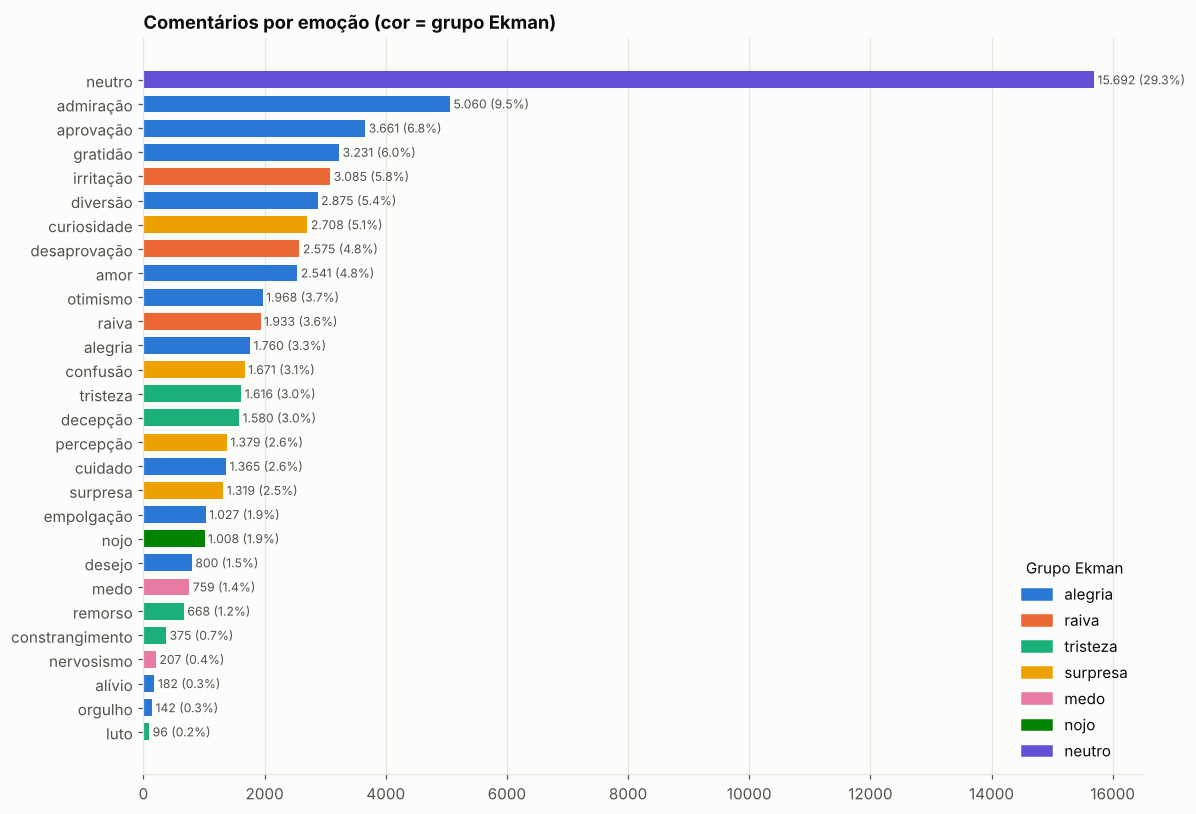

In [10]:
freq = data["emotions"].explode().value_counts()
fig, ax = plt.subplots(figsize=(11, 7.5))
ax.barh([PT[e] for e in freq.index[::-1]], freq.values[::-1],
        color=[EKMAN_COLOR[EMO2EKMAN[e]] for e in freq.index[::-1]], height=0.7)
for y, v in enumerate(freq.values[::-1]):
    ax.text(v, y, f" {fmt(v)} ({v/len(data):.1%})", va="center", fontsize=8, color=INK2)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=EKMAN_COLOR[g]) for g in EKMAN_ORDER],
          [PT_EKMAN[g] for g in EKMAN_ORDER], title="Grupo Ekman", frameon=False, loc="lower right")
ax.set_title("Comentários por emoção (cor = grupo Ekman)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

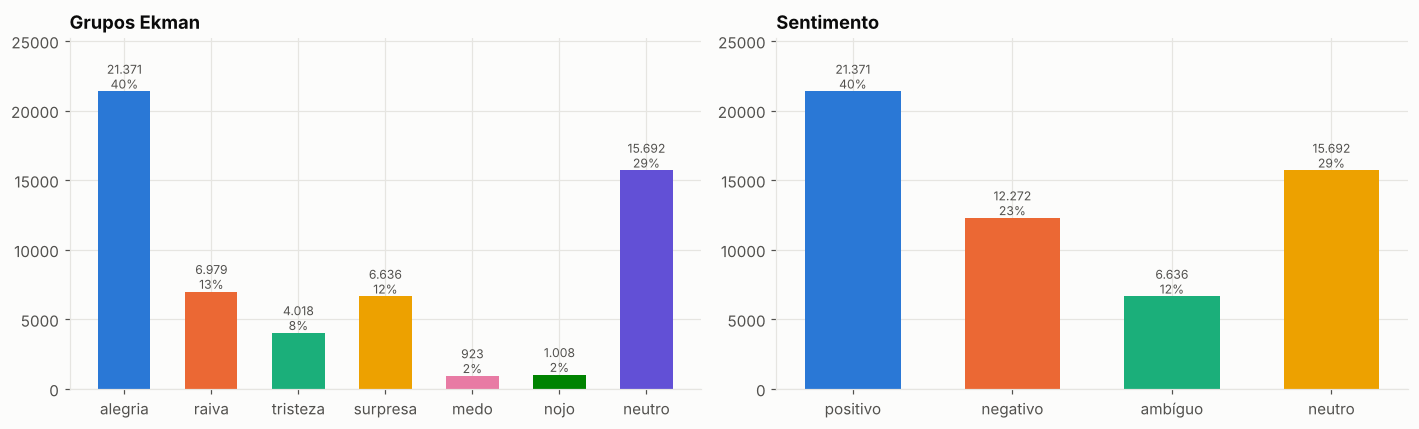

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, order, colors, names, title in [
        (axes[0], "ekman", EKMAN_ORDER, EKMAN_COLOR, PT_EKMAN, "Grupos Ekman"),
        (axes[1], "sentiment", SENT_ORDER, SENT_COLOR, PT_SENT, "Sentimento")]:
    c = data[col].explode().value_counts().reindex(order)
    ax.bar([names[k] for k in c.index], c.values, color=[colors[k] for k in c.index], width=0.6)
    for i, v in enumerate(c.values):
        ax.text(i, v, f"{fmt(v)}\n{v/len(data):.0%}", ha="center", va="bottom", fontsize=8, color=INK2)
    ax.set_title(title); ax.set_ylim(0, c.max() * 1.18)
plt.tight_layout(); plt.show()

### 6.2 Multi-rótulo e emoções que andam juntas

Comentários com mais de uma emoção: 13.4%
Comentários com sentimento positivo E negativo ao mesmo tempo: 1.023 (1.9%)


,text,emotions_pt
28838,"eu pessoalmente não acho que isso seja verdade, mas obrigado por compartilhar sua visão sobre isso.","[desaprovação, gratidão]"
6947,... Não sinto que o seu comentário seja de um ponto de vista objetivo... Mas obrigado de qualquer forma.,"[desaprovação, gratidão]"
51088,"Saudades do [NAME], tomara que a gente pudesse trocar de volta por ele!","[desejo, luto]"
26785,Isso é aterrorizante. Boa sorte pra você e sua família. Tomara que descubram logo quem são esses esquisitos.,"[medo, otimismo]"
41560,Isso é nota 10 só pelo conceito. Mal posso esperar pra ver se é bom mesmo.,"[desaprovação, empolgação]"


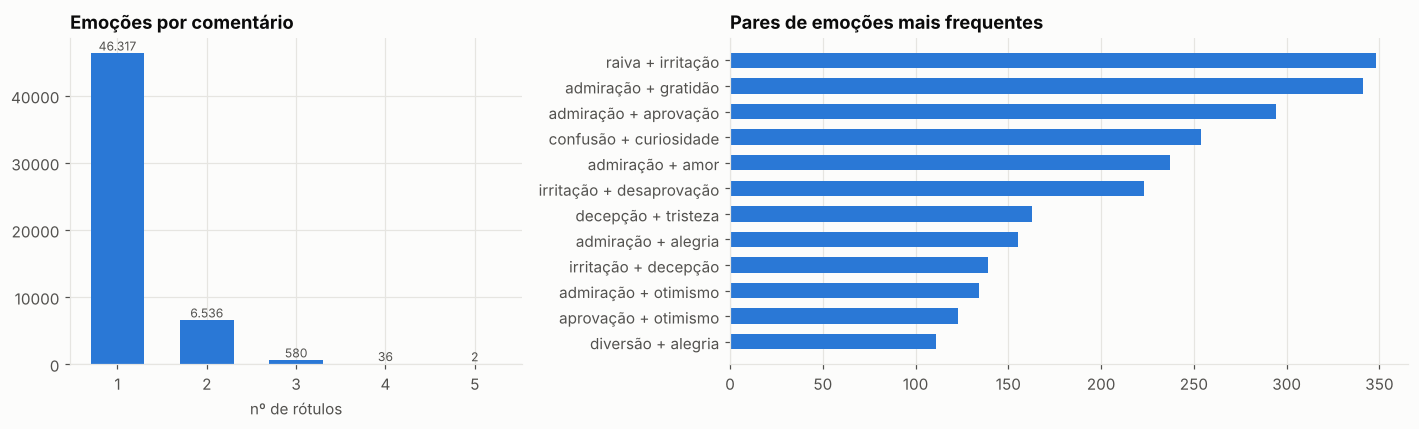

In [12]:
nl = data["n_labels"].value_counts().sort_index()
mixed = data["sentiment"].map(lambda s: "positive" in s and "negative" in s)
print(f"Comentários com mais de uma emoção: {(data.n_labels > 1).mean():.1%}")
print(f"Comentários com sentimento positivo E negativo ao mesmo tempo: {fmt(mixed.sum())} ({mixed.mean():.1%})")
display(amostra_segura(data.loc[mixed, ["text", "emotions_pt"]], 5, random_state=3))

pairs = Counter(p for l in data["emotions"] if len(l) > 1 for p in combinations(sorted(l), 2))
top = pd.Series({f"{PT[a]} + {PT[b]}": n for (a, b), n in pairs.most_common(12)})
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 1.5]})
axes[0].bar(nl.index.astype(str), nl.values, color=PAL[0], width=0.6)
for i, v in enumerate(nl.values): axes[0].text(i, v, fmt(v), ha="center", va="bottom", fontsize=8, color=INK2)
axes[0].set_title("Emoções por comentário"); axes[0].set_xlabel("nº de rótulos")
axes[1].barh(top.index[::-1], top.values[::-1], color=PAL[0], height=0.6)
axes[1].set_title("Pares de emoções mais frequentes"); axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

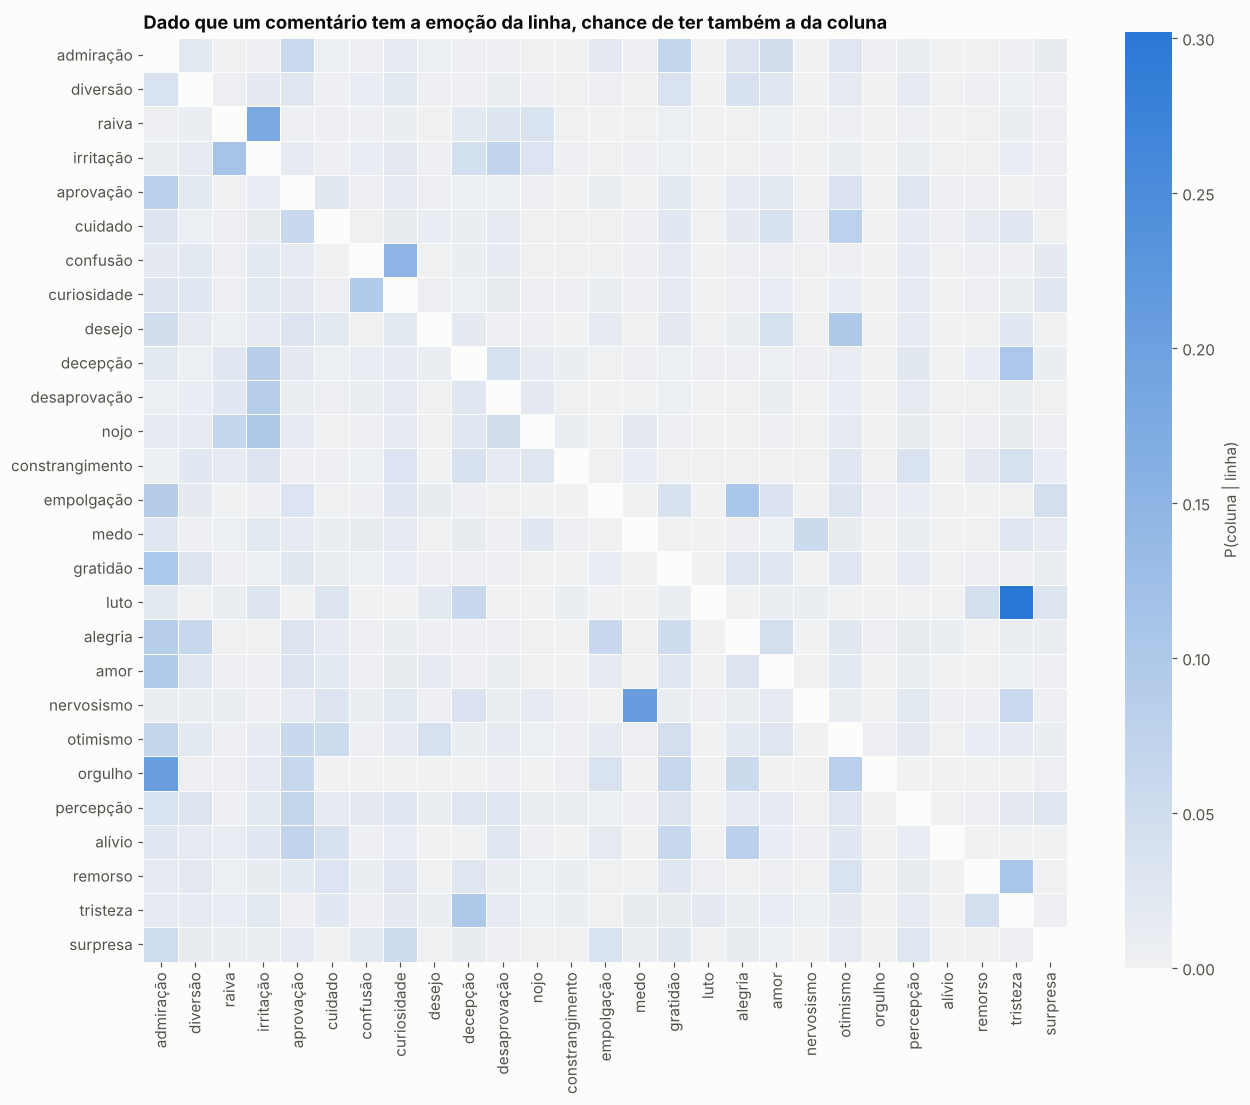

In [13]:
mh = data[EMOTIONS[:-1]]
co = mh.T @ mh
cond = (co / np.diag(co)[:, None]).mask(np.eye(len(co), dtype=bool))
cond.index = cond.columns = [PT[e] for e in co.index]
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(cond, cmap=SEQ, ax=ax, linewidths=0.5, linecolor=SURF, square=True,
            cbar_kws={"label": "P(coluna | linha)"})
ax.set_title("Dado que um comentário tem a emoção da linha, chance de ter também a da coluna"); ax.grid(False)
plt.tight_layout(); plt.show()

### 6.3 Tamanho dos comentários

,count,mean,std,min,25%,50%,75%,max
n_chars,53471.0,75.0,39.4,5.0,43.0,72.0,104.0,711.0
n_words,53471.0,13.6,7.0,1.0,8.0,13.0,19.0,43.0


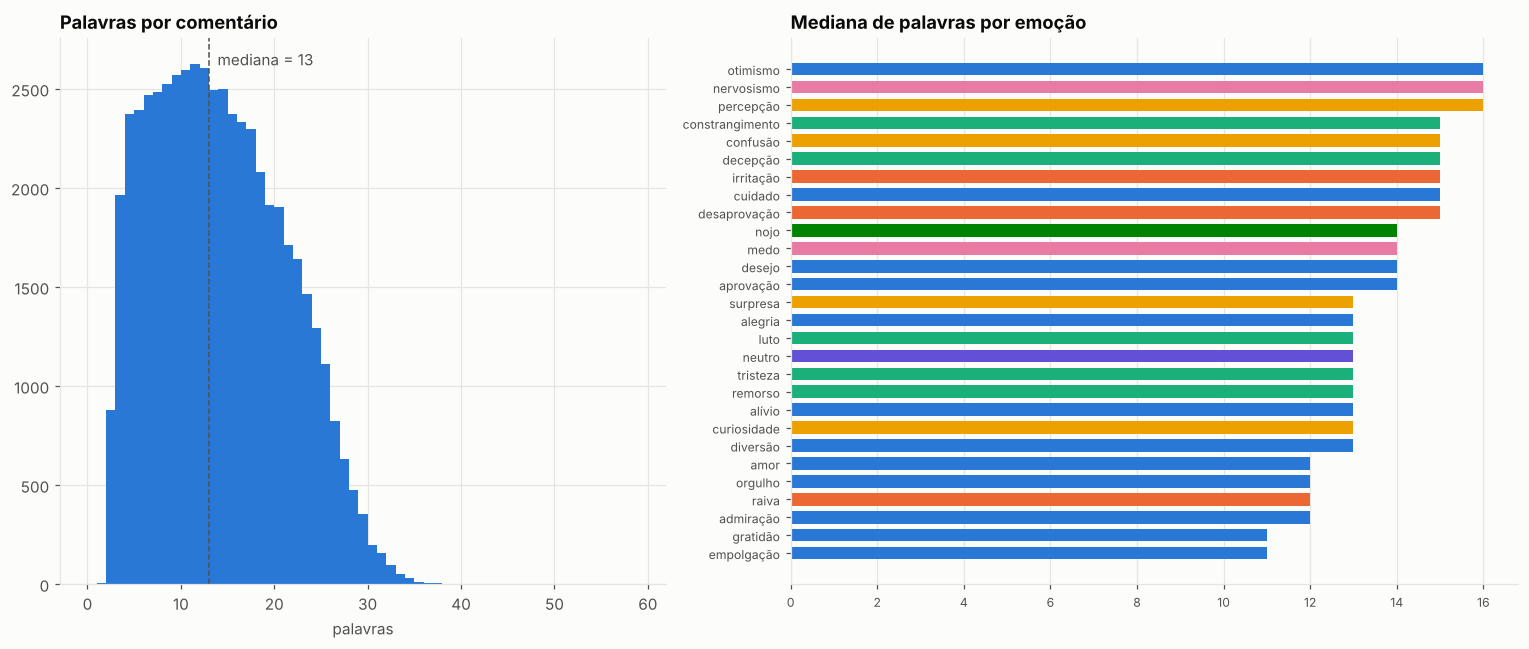

In [14]:
display(data[["n_chars", "n_words"]].describe().round(1).T)
med = data.explode("emotions").groupby("emotions")["n_words"].median().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.2]})
axes[0].hist(data["n_words"], bins=range(0, 60), color=PAL[0])
axes[0].axvline(data["n_words"].median(), color=INK2, ls="--", lw=1)
axes[0].text(data["n_words"].median(), axes[0].get_ylim()[1] * 0.95, f"  mediana = {data['n_words'].median():.0f}", color=INK2)
axes[0].set_title("Palavras por comentário"); axes[0].set_xlabel("palavras")
axes[1].barh([PT[e] for e in med.index], med.values, color=[EKMAN_COLOR[EMO2EKMAN[e]] for e in med.index], height=0.7)
axes[1].set_title("Mediana de palavras por emoção"); axes[1].grid(axis="y", visible=False); axes[1].tick_params(labelsize=8)
plt.tight_layout(); plt.show()

### 6.4 Como cada emoção é escrita

Marcadores de estilo por grupo: exclamação, pergunta, palavras em CAIXA ALTA, risada (`kkk`, `haha`, `rs`),
emoji/emoticon, palavrão e menção a pessoa (`[NAME]`). Valores = % dos comentários do grupo que têm o marcador.

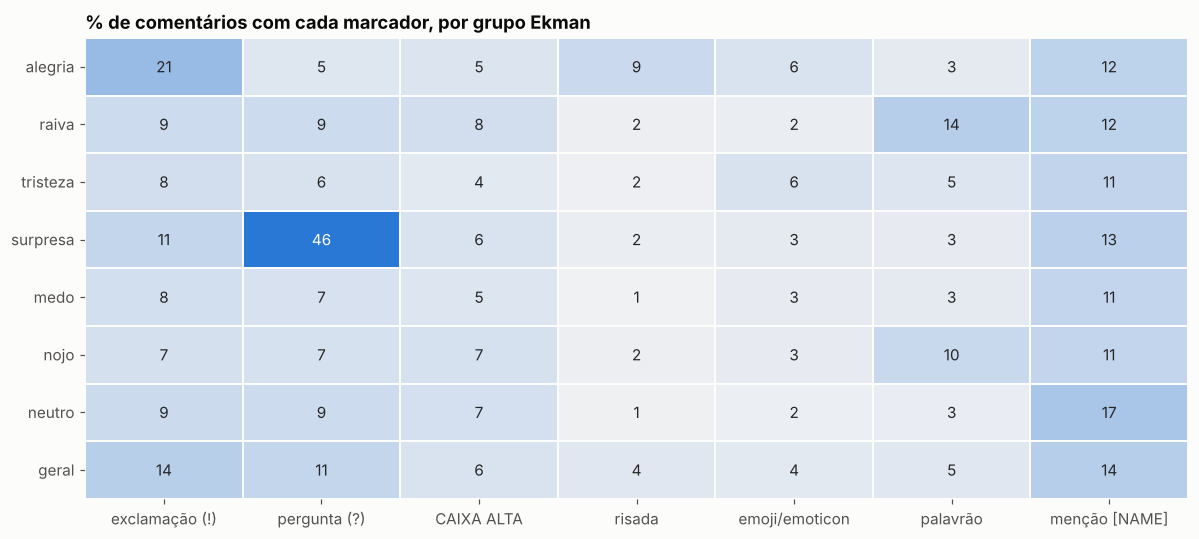

In [15]:
PROFANITY = r"\b(?:porra|caralho|merda|foda\w*|fod[ei]\w*|puta|bosta|cacete|droga|desgra[çc]\w*|vtnc|pqp|fdp|cu)\b"
MARKERS = {
    "exclamação (!)":   lambda s: s.str.contains("!", regex=False),
    "pergunta (?)":     lambda s: s.str.contains("?", regex=False),
    "CAIXA ALTA":       lambda s: s.str.replace(r"\[[A-Z_]+\]", "", regex=True).str.contains(r"\b[A-ZÁÉÍÓÚÂÊÔÃÕÇ]{3,}\b", regex=True),
    "risada":           lambda s: s.str.contains(r"(?i)\b(?:k{3,}|(?:ha){2,}h?|(?:he){2,}|rs+|lol|lmao)\b", regex=True),
    "emoji/emoticon":   lambda s: s.str.contains(r"[\U0001F300-\U0001FAFF☀-➿]|[:;]-?[()DPp]|<3", regex=True),
    "palavrão":         lambda s: s.str.contains(PROFANITY, case=False, regex=True),
    "menção [NAME]":    lambda s: s.str.contains(r"\[NAME\]", regex=True),
}
for k, f in MARKERS.items():
    data["has_" + k] = f(data["text"])
mk_cols = ["has_" + k for k in MARKERS]

by_ek = data.explode("ekman").groupby("ekman")[mk_cols].mean().reindex(EKMAN_ORDER) * 100
by_ek.index = [PT_EKMAN[g] for g in by_ek.index]; by_ek.columns = list(MARKERS)
by_ek.loc["geral"] = data[mk_cols].mean().values * 100
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(by_ek, annot=True, fmt=".0f", cmap=SEQ, linewidths=1, linecolor=SURF, cbar=False, ax=ax)
ax.set_title("% de comentários com cada marcador, por grupo Ekman"); ax.grid(False); ax.set_ylabel("")
plt.tight_layout(); plt.show()
data = data.drop(columns=mk_cols)

### 6.5 Palavras características de cada grupo

Em vez da frequência bruta (que repete palavras genéricas como "tão" e "parece" em todos os grupos), usamos o
**log-odds** de cada palavra no grupo contra o resto do dataset: aparecem as palavras que mais *distinguem* o grupo.
Palavrões e termos ofensivos ficam fora dos gráficos.

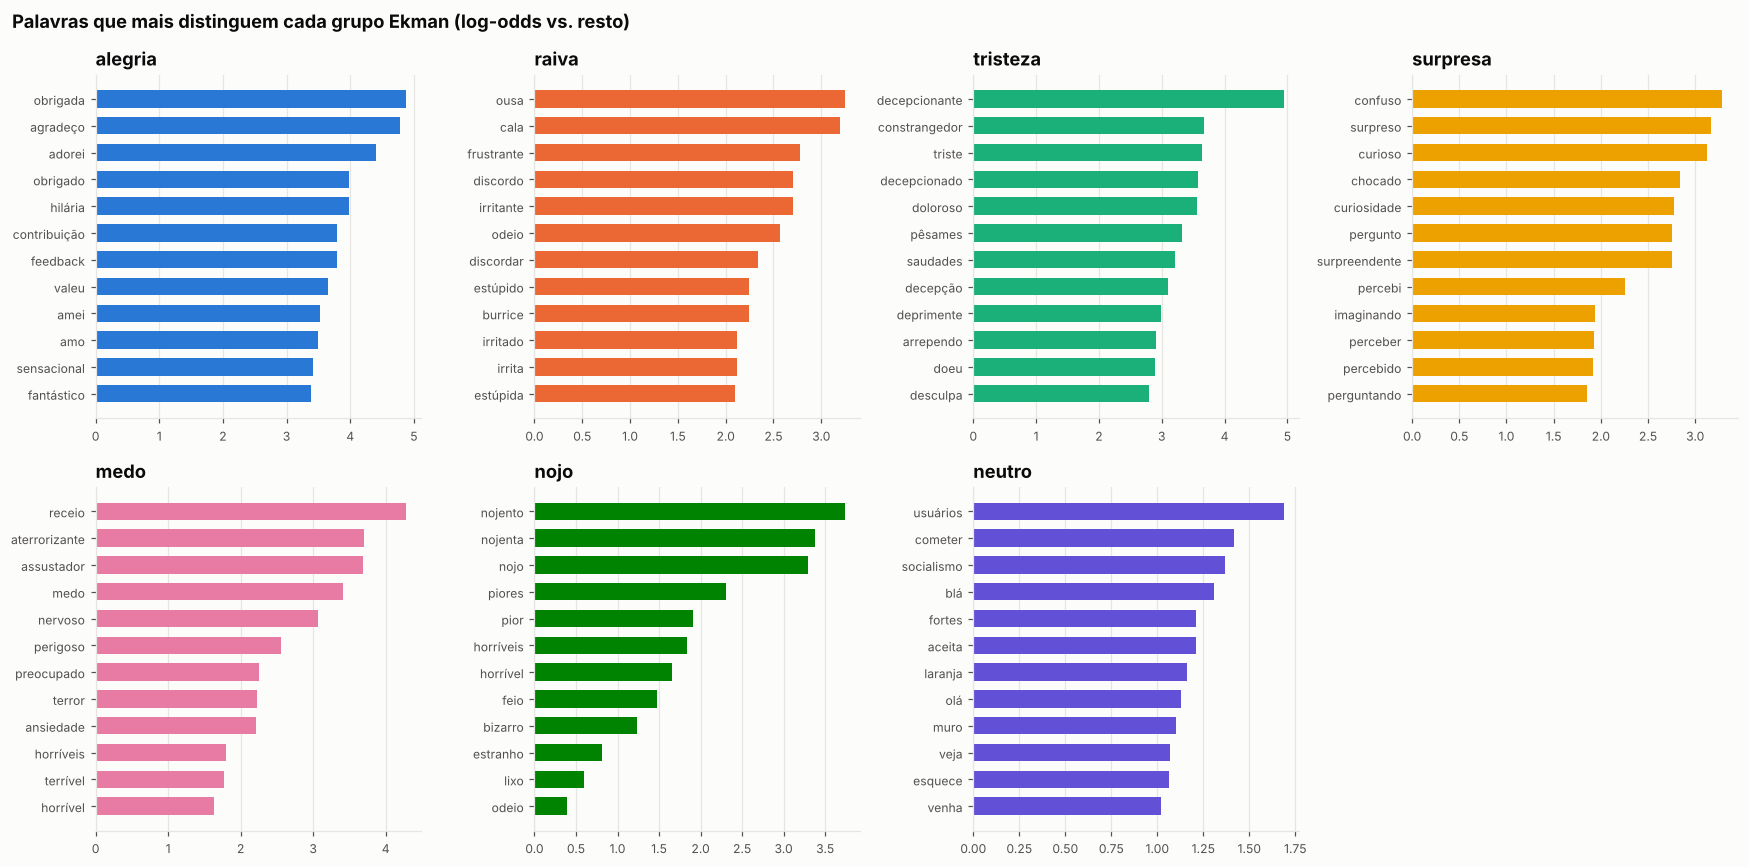

In [16]:
STOP_PT = set("""a à ao aos as às até com como da das de dele dela deles delas do dos e é em entre era eram essa esse
esta este eu ela ele elas eles foi for há isso isto já la lá lhe mais mas me mesmo meu minha muito na nas não nem no
nos nós num numa o os ou para pela pelas pelo pelos por qual quando que quem se sem ser seu sua são só também te tem
tá ter teu tua tu um uma umas uns você vocês vai vou está estão estou to ta pra pro tô aí ai então bem assim aqui tipo
cara gente coisa tudo nada sim fazer faz sei acho ainda agora sobre dá dar mim seus suas nossa nosso porque quê vc
aquele aquela depois antes vez vai pode tava tinha tenho isso""".split())
tok = lambda t: [w for w in WORD_RE.findall(PLACEHOLDER_RE.sub(" ", t).lower()) if w not in STOP_PT and len(w) > 2 and not CONTEUDO_PESADO.fullmatch(w)]
data["_tok"] = data["text"].map(tok)

def distinctive(mask, k=12, min_count=15, alpha=0.5):
    g = Counter(w for t in data.loc[mask, "_tok"] for w in t)
    r = Counter(w for t in data.loc[~mask, "_tok"] for w in t)
    V = len(set(g) | set(r)); Ng, Nr = sum(g.values()), sum(r.values())
    sc = {w: np.log((c + alpha) / (Ng + alpha * V)) - np.log((r[w] + alpha) / (Nr + alpha * V))
          for w, c in g.items() if c >= min_count}
    s = pd.Series(sc).nlargest(k)
    return s[s > 0]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, grp in zip(axes.flat, EKMAN_ORDER):
    s = distinctive(data["ekman"].map(lambda e: grp in e))
    ax.barh(s.index[::-1], s.values[::-1], color=EKMAN_COLOR[grp], height=0.65)
    ax.set_title(PT_EKMAN[grp]); ax.grid(axis="y", visible=False); ax.tick_params(labelsize=8)
axes.flat[-1].axis("off")
plt.suptitle("Palavras que mais distinguem cada grupo Ekman (log-odds vs. resto)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

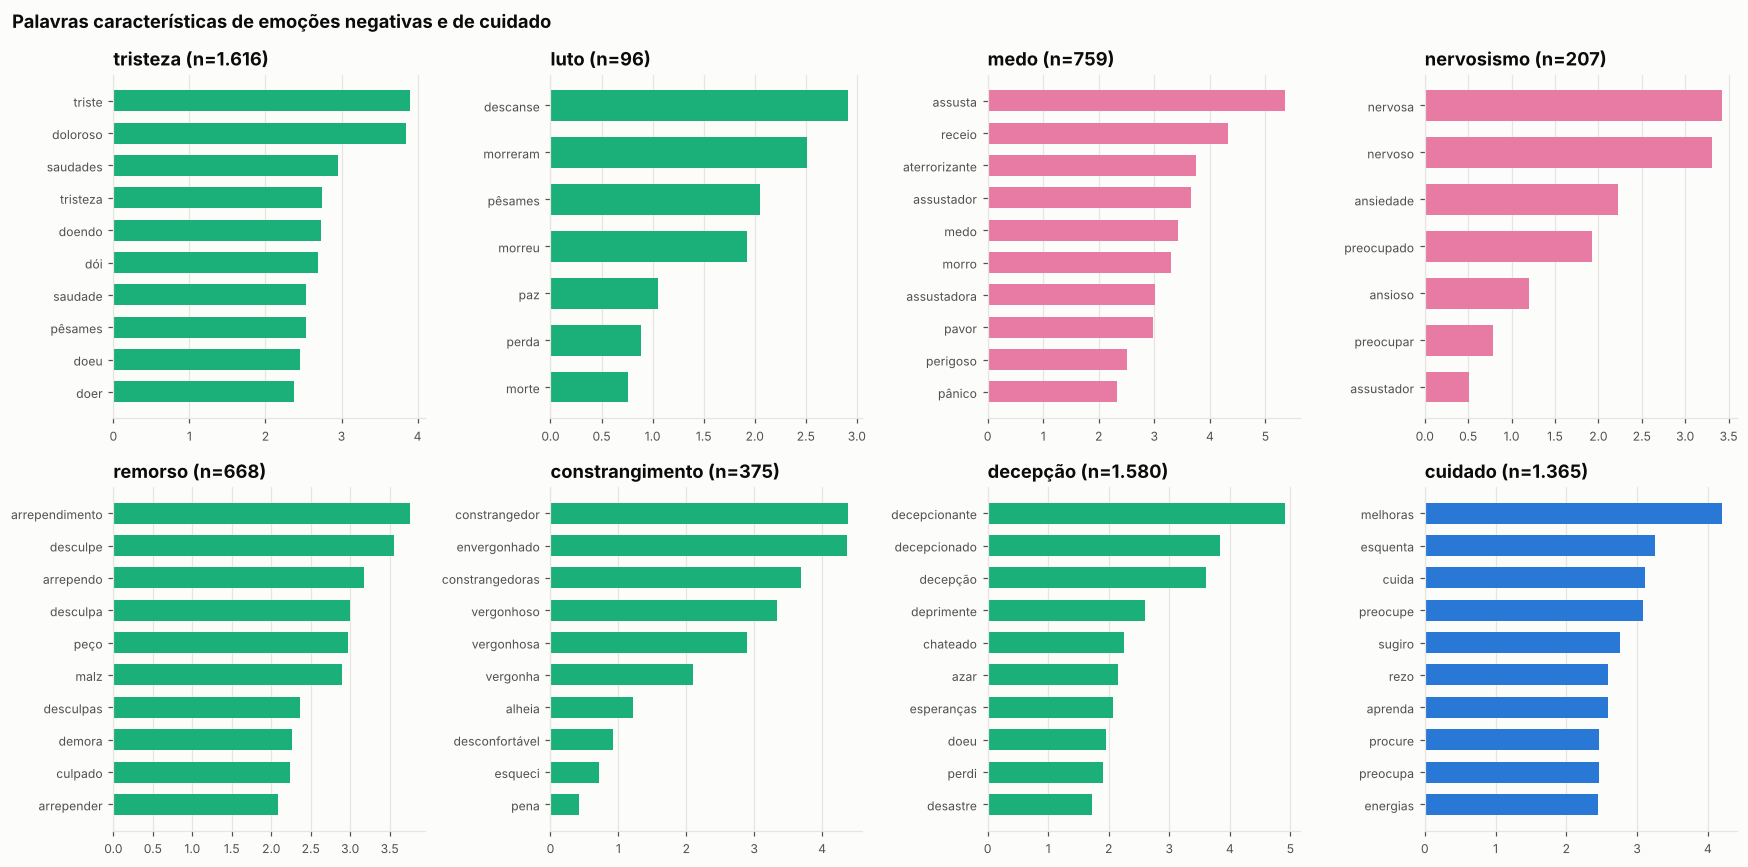

In [17]:
# Mesma análise para as emoções mais ligadas a bem-estar emocional
FOCO = ["sadness", "grief", "fear", "nervousness", "remorse", "embarrassment", "disappointment", "caring"]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, e in zip(axes.flat, FOCO):
    s = distinctive(data[e] == 1, k=10, min_count=5)
    ax.barh(s.index[::-1], s.values[::-1], color=EKMAN_COLOR[EMO2EKMAN[e]], height=0.65)
    ax.set_title(f"{PT[e]} (n={fmt(data[e].sum())})"); ax.grid(axis="y", visible=False); ax.tick_params(labelsize=8)
plt.suptitle("Palavras características de emoções negativas e de cuidado", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()
data = data.drop(columns="_tok")

### 6.6 Exemplos por grupo

In [18]:
for grp in EKMAN_ORDER:
    print(f"\n## {PT_EKMAN[grp]}")
    sub = data[data["ekman"].map(lambda e: e == [grp])]
    for t in amostra_segura(sub, 4, random_state=8)["text"]: print("  -", t)


## alegria


  - Quero uma camiseta que diga "Brilhante, Linda, Feroz, Um Espanto". Isso sim é poder.
  - Esse cara entende de entretenimento esportivo.
  - Valeu pela informação, eu tava pensando a mesma coisa.
  - Isso é fantástico!

## raiva
  - Em 10 anos, ela ainda vai ser uma perdedora.
  - Como alguém já mencionou, tecnicamente não é roubo. Então isso provavelmente só vai me arrumar mais problemas.
  - Acho que o título foi só mal redigido, o que eu entendi foi que tinha um motivo além de ensinar as crianças a contar.
  - Droga, [NAME] de novo...

## tristeza
  - Esses vazamentos são bem confiáveis, na verdade. É triste que vocês deixem o ódio e a raiva cegarem vocês de aproveitar a experiência.
  - Droga, você foi mais rápido.
  - como stan de kpop e army, tô muito decepcionado
  - O hip hop decaiu tanto, a música em geral, desde os anos 90.

## surpresa
  - Achei que fosse ilegal praticar ninjutsu
  - [NAME], o que é o "curto prazo" versus o "longo prazo"?
  - Entre isso e a manchete, eu m

  - Tô sentindo a mesma coisa sobre os Nets e os Hornets. Só me preocupa que os Hornets não consigam cobrir o handicap
  - Demonizar - retratar como perverso e ameaçador. Não é difícil demonizar alguém quando a pessoa se demoniza regularmente.
  - Quando foi que a Alt-Right foi classe trabalhadora? São sempre os caras brancos mais ricos que são socialmente um desastre.
  - Que orelhas... que orelhas horríveis

## nojo
  - Isso é nojento. *fica excitado secretamente* Chega desse sub. *abre uma aba anônima*
  - Juro que já vi isso num cartaz em algum lugar na minha escola, é horrível.
  - Terminar de fazer xixi e ainda continuar com vontade de fazer xixi.
  - Isso é nojento.... por favor façam mais.

## neutro


  - Bom, tem aquele ditado antigo, né: quem sabe, faz. Quem não sabe, ensina.
  - Lembrando que o exército incel do [NAME] literalmente agrediu fisicamente os fãs do [NAME] quando ela falou no leste de LA, incluindo crianças.
  - Repare como nenhum deles tem filhos
  - Isso é porque você não é um político eleito. Aprenda esse truque simples!


## 7. Exportação

In [19]:
os.makedirs(OUT_DIR, exist_ok=True)
front = ["id", "split_original", "text",
         "emotions", "emotions_pt", "ekman", "sentiment", "n_labels", "n_chars", "n_words"]
data = data[front + EMOTIONS]
data.to_json(os.path.join(OUT_DIR, "goemotions_ptbr_unificado.jsonl"), orient="records", lines=True, force_ascii=False)
out_csv = data.copy()
for c in ["emotions", "emotions_pt", "ekman", "sentiment"]:
    out_csv[c] = out_csv[c].str.join(",")
out_csv.to_csv(os.path.join(OUT_DIR, "goemotions_ptbr_unificado.csv"), index=False)
print(os.listdir(OUT_DIR), data.shape)

['goemotions_ptbr_unificado.csv', 'goemotions_ptbr_unificado.jsonl'] (53471, 38)


In [20]:
# Divisão original do GoEmotions -> train/validation/test.csv (entrada do notebook da rede neural).
# Como textos repetidos viraram uma linha só, o mesmo texto não aparece em dois splits (sem vazamento).
SPLITS = {"train": "train", "dev": "validation", "test": "test"}
cols_out = ["id", "text"] + EMOTIONS
for sp, name in SPLITS.items():
    data.loc[data.split_original == sp, cols_out].to_csv(os.path.join(OUT_DIR, f"{name}.csv"), index=False)
display(data["split_original"].map(SPLITS).value_counts().reindex(SPLITS.values()).rename("comentários").to_frame())
print(sorted(os.listdir(OUT_DIR)))

,comentários
split_original,
train,42737
validation,5377
test,5357


['goemotions_ptbr_unificado.csv', 'goemotions_ptbr_unificado.jsonl', 'test.csv', 'train.csv', 'validation.csv']


In [21]:
# resumo numérico para as conclusões
r = {
    "comentários": len(data),
    "% neutro": data["neutral"].mean(),
    "% multi-rótulo": (data.n_labels > 1).mean(),
    "positivo": data["sentiment"].map(lambda s: "positive" in s).mean(),
    "negativo": data["sentiment"].map(lambda s: "negative" in s).mean(),
    "classes com < 300 exemplos": [PT[e] for e in EMOTIONS if data[e].sum() < 300],
}
r

{'comentários': 53471,
 '% neutro': np.float64(0.2934674870490546),
 '% multi-rótulo': np.float64(0.1337921490153541),
 'positivo': np.float64(0.3996745899646537),
 'negativo': np.float64(0.22950758354996167),
 'classes com < 300 exemplos': ['luto', 'nervosismo', 'orgulho', 'alívio']}

## 8. Conclusões e pontos de melhoria

**Sobre os dados**
- A base veio íntegra (sem nulos, ids duplicados ou rótulos inconsistentes). O tratamento removeu só **792 comentários (1,5%)**, e o dataset unificado ficou com **53.471**.
- **29% dos comentários são neutros.** Entre os que têm emoção, predominam as positivas: **40% positivo, 23% negativo, 12% ambíguo** (surpresa, confusão, curiosidade, percepção).
- O desbalanceamento é forte nas 28 emoções: `luto` tem 96 exemplos, e `nervosismo`, `orgulho` e `alívio` têm menos de 300. Em Ekman, `medo` (923) e `nojo` (1.008) são as menores classes.
- **13% dos comentários têm mais de uma emoção.** Os pares mais comuns são variações da mesma família (raiva + irritação, admiração + gratidão, confusão + curiosidade). Cerca de 2% misturam positivo e negativo (por exemplo, gratidão + desaprovação).
- Os comentários são curtos: **mediana de 13 palavras**. Agradecimento, admiração e empolgação são os mais curtos; otimismo, nervosismo e percepção, os mais longos.

**Como as emoções aparecem no texto**
- **Surpresa** é guiada por perguntas: 46% dos comentários têm "?". **Alegria** puxa exclamação (21%) e risada. **Raiva** e **nojo** concentram palavrões (14% e 10%).
- As palavras que distinguem cada grupo fazem sentido (tristeza: *decepcionante, triste, saudades, pêsames*; medo: *receio, assustador, ansiedade*; raiva: *cala, odeio, discordo*). Isso indica que a tradução preservou bem o sinal emocional.
- **Neutro** não tem vocabulário próprio forte. Ele é definido pela *ausência* de marcas emocionais, o que costuma confundir modelos.

**Sobre `ekman` e `sentiment`:** vale manter as duas. A razão entre a classe mais comum e a mais rara cai de 163x (28 emoções) para 23x (Ekman) e 3x (sentimento).

**Próximos passos sugeridos**
1. Reforçar as classes raras (`medo`, `nojo`, `luto`, `nervosismo`) com frases escritas em português (paráfrases geradas e revisadas, ou outro dataset em pt-BR).
2. Treinar o classificador com `train.csv` / `validation.csv` e avaliar no `test.csv` com F1 macro, olhando de perto as classes raras.

**Limitações observadas**
- Os rótulos têm ruído herdado do GoEmotions (ex.: "Esse é o meu xingamento favorito" rotulado como tristeza), e textos idênticos às vezes têm rótulos diferentes.
- O conteúdo é do Reddit em inglês adaptado: há muitos temas americanos (esportes, política dos EUA) e linguagem ofensiva.
- É conteúdo de discussão, não de desabafo: faltam frases em primeira pessoa como "tô me sentindo sozinho" ou "não consigo dormir de ansiedade".